# 시계열 분석

# 1. 시계열 데이터란?

## 1-1. 시계열 데이터의 정의

> **시계열 데이터**: 시간의 흐름에 따라 일정한 간격과 순서로 관측·기록된 데이터

- 주가, 기온, 매출처럼 같은 대상을 여러 시점에 걸쳐 반복 관측한 데이터
- **시간 순서가 의미를 가짐** → 순서를 섞으면 변화의 흐름과 패턴이 사라짐
- 매일, 매월, 매년 등 일정한 관측 간격을 바탕으로 시점 간 비교
- 횡단면 데이터는 한 시점의 여러 대상을 관찰하지만, 시계열 데이터는 한 대상의 여러 시점을 관찰

### 시계열 데이터의 종류

**1. 단변량 시계열**

- 시간에 따라 **하나의 변수**를 관측한 데이터
- 자기 자신의 과거 값만으로 미래를 예측
- 예: 일별 주가, 일별 평균 기온, 카페의 일별 판매량

**2. 다변량 시계열**

- 시간에 따라 **여러 변수**를 동시에 관측한 데이터
- 자기 자신의 과거 값뿐 아니라 다른 변수의 영향까지 고려
- 예: 판매량 예측에 기온, 강수량, 요일 등을 함께 활용
- 변수가 많다고 항상 좋은 것은 아니며, 미래 시점에도 해당 변수의 값을 알 수 있는지 고려해야 함

### 시계열 분석의 목적

> 시간 순서대로 쌓인 데이터에서 패턴을 찾아내고 이를 바탕으로 **미래 값을 예측**하는 분석 방법

- **기본 가정**: 과거의 패턴이 미래에도 어느 정도 반복될 것이라는 가정
- 가까운 미래보다 먼 미래의 예측에서 불확실성이 커질 수 있음
- 금융, 유통, 에너지, 기상, 서비스 운영 등에서 미래 수요와 변화를 예측해 의사결정에 활용

**분석 흐름**

시계열 이해 → 결측치·이상치 처리 및 전처리 → 정상성 판단과 확보 → 모델링 및 예측

## 1-2. 시계열 데이터의 특징

### 1. 시간의존성

> 현재 시점의 값이 과거 시점의 값에 영향을 받는 성질

- 과거 값이 현재 값에 영향을 주며, 가까운 과거의 영향이 더 큰 경우가 많음
- 시간의 순서를 섞으면 의미가 달라지므로 무작위로 학습·평가 데이터를 나누면 안 됨
- 과거 데이터로 학습하고 미래 데이터로 평가해야 **데이터 누수** 방지 가능

### 2. 계절성과 추세

**계절성**

- 일정한 주기로 비슷한 패턴이 반복되는 성질
- 예: 여름마다 증가하는 아이스크림 판매량

**추세**

- 시간의 흐름에 따라 데이터가 장기적으로 증가하거나 감소하는 방향성
- 예: 장기간 증가하는 스마트폰 보급률

→ 계절성은 **언제마다 반복되는지**, 추세는 **어느 방향으로 움직이는지**를 나타냄

### 3. 자기상관성

> 같은 시계열의 현재 값과 과거 값이 얼마나 비슷하게 움직이는지를 나타내는 정도

- 오늘 판매량과 어제 판매량처럼 동일한 변수의 서로 다른 시점을 비교
- 자기상관계수는 -1에서 1 사이의 값을 가짐
  - 1에 가까움: 과거 값이 높으면 현재 값도 높은 경향
  - -1에 가까움: 과거 값이 높으면 현재 값은 낮은 경향
  - 0에 가까움: 과거 값과 현재 값의 관계가 약함
- **시차**: 현재 시점과 비교하는 과거 시점 사이의 간격
  - 일별 데이터에서 어제와 비교하면 시차 1, 일주일 전과 비교하면 시차 7
- 시차별 자기상관을 분석해 반복 주기와 계절성을 파악 가능

**자기상관성이 일반 회귀분석에 미치는 영향**

- 오차항 사이의 상관관계로 독립성 가정이 깨져 검정과 신뢰구간이 왜곡될 수 있음
- 함께 증가하는 두 시계열이 실제 관계가 없어도 높은 상관관계를 보이는 **허위 상관관계** 발생 가능
- 과거 값의 영향과 누적되는 예측 오차까지 고려해야 해 모델이 복잡해짐

→ 시계열 전용 모델을 사용하거나 차분, 추세 제거 등 전처리 후 분석

## 1-3. 시계열 데이터의 분석 요인  
  
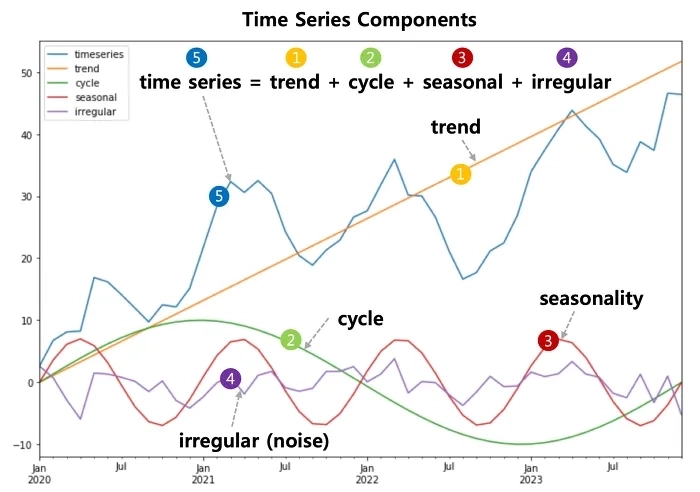  
  
### 1. 추세 요인

- 시계열이 장기간 증가하거나 감소하는 경향
- 짧은 변동보다 전체적인 방향을 나타냄
- 예: 인구 변화, 물가 상승, 출생아 수 감소

### 2. 계절 요인

- **1년 이내의 일정한 주기**로 반복되는 변동
- 날씨, 요일, 공휴일, 명절 등에 의해 발생
- 예: 여름 에어컨 판매량 증가, 주말 대학가 식당 매출 감소

### 3. 순환 요인

- 계절성보다 길고 **주기가 일정하지 않은** 반복적 변동
- 보통 수년에 걸친 경기 호황·불황 등에서 나타남
- 주기가 길고 불규칙해 추세와 구분하기 어려움
- 요소분해에서는 순환 요인을 추세에 포함해 다루는 경우가 많음

### 4. 불규칙 요인

- 추세, 계절, 순환 요인으로 설명되지 않는 나머지 움직임
- **잔차 또는 노이즈**라고도 함
- 예: 갑작스러운 폭우, 예상하지 못한 유명인의 방문으로 인한 매출 변화

→ 실제 시계열은 여러 요인이 결합된 형태이며, 이를 분리해 살펴보는 과정이 **요소분해**

# 2. 시계열 데이터 전처리

> 시계열 데이터의 시간적 흐름과 패턴을 왜곡하지 않도록 결측치, 이상치, 노이즈 등을 처리하는 과정

- 특정 시점의 값이 빠지거나 튀는 경우 주변 시점의 분석까지 영향을 받을 수 있음
- 데이터 확인 → 결측치 처리 → 이상치 처리 → 평활화 → 요소분해 → 정상성 판단 및 확보 순으로 진행

## 2-1. 결측치와 이상치 탐지 및 처리

### 1. 결측치

> 특정 시점의 관측값이 수집되지 않았거나 누락된 상태

- 결측 행을 삭제하면 시간 간격이 깨질 수 있음
- 전체 평균으로 대체하면 시간 흐름과 계절성이 반영되지 않음
- 앞뒤 관측값과 추세를 고려해 값을 채우는 **보간법**이 주로 사용됨

**결측치 처리 방법**

- **삭제**: 결측 시점을 제거하는 방법 → 관측 간격이 깨질 수 있음
- **단순 대치**: 평균, 중앙값, 최빈값으로 대체 → 시간 흐름을 반영하지 못함
- **보간**: 앞뒤 관측값을 이용해 비어 있는 값을 추정
- **이동평균 대치**: 주변 일정 구간의 평균으로 결측값 대체
- **머신러닝 기법**: 주변 변수와 패턴을 학습해 결측값 예측 → 계산량과 복잡도 증가

### 보간법의 종류

**1. 선형 보간법**

- 두 관측점을 직선으로 연결해 중간 값을 추정하는 방식
- 계산이 빠르고 직관적이지만 급격한 변화나 비선형 패턴에는 부적합
- 예: 2일 판매량 110, 4일 판매량 130이면 3일을 120으로 추정

**2. 다항식 보간법**

- 여러 관측점을 통과하는 다항식을 이용해 중간 값 추정
- 비선형 관계를 표현할 수 있지만 차수가 높으면 과적합과 불안정한 변동 발생 가능

**3. 스플라인 보간법**

- 구간별 다항식을 이어 부드러운 곡선으로 값을 추정
- 곡선 형태의 데이터에 유용하지만 계산과 구현이 상대적으로 복잡

**4. 조각별 상수 보간법**

- 각 구간에서 일정한 값을 유지하는 방식
- 직전 값 유지, 직후 값 유지, 가장 가까운 관측값 사용 등의 방법
- 계산이 단순하지만 계단형으로 나타나 세밀한 변화 표현이 어려움

**보간과 회귀의 차이**

- 보간은 기존 관측점을 반드시 통과하도록 값을 연결
- 회귀는 관측점과의 전체 오차를 줄이는 함수를 찾으므로 모든 관측점을 통과할 필요는 없음

### 2. 이상치

> 시계열의 일반적인 패턴에서 크게 벗어난 극단적인 값

- 시계열은 같은 값이라도 시점에 따라 정상 또는 이상치로 판단될 수 있음
- 예: 8월의 기온 35도는 자연스럽지만 1월의 기온 35도는 이상치 가능성이 높음
- 값의 크기뿐 아니라 **추세와 계절성**을 함께 고려해야 함

### 이상치 탐지 방법

**1. 사분위수 범위**

- 제1사분위수와 제3사분위수 사이의 범위를 기준으로 극단적인 값 탐지
- 기준: 제1사분위수 − 1.5 × 사분위수 범위 미만 또는 제3사분위수 + 1.5 × 사분위수 범위 초과
- 계산이 간단하지만 추세와 계절성이 강한 데이터에는 그대로 적용하기 어려움

**2. 표준점수**

- 관측값이 평균에서 표준편차의 몇 배만큼 떨어져 있는지 계산
- 일반적으로 절댓값이 3보다 크면 이상치로 판단
- 평균과 표준편차 자체가 이상치의 영향을 받을 수 있음
- 이동평균과 이동 표준편차를 활용하면 시점에 따른 변화 반영 가능

**3. STL 분해**

- 시계열을 추세, 계절, 잔차로 분리한 뒤 잔차가 크게 벗어난 시점을 이상치로 탐지
- 추세와 계절성이 뚜렷한 데이터에 적합하지만 계산 비용이 큼

### 이상치 탐지 모델

- **분류 및 회귀 트리**: 과거 데이터를 바탕으로 예측한 값과 실제 값의 차이가 큰 시점을 탐지
- **군집화 기반 탐지**: 군집 중심에서 멀거나 밀집 영역에 속하지 못하는 데이터를 이상치로 판단
- **오토인코더**: 정상 패턴을 압축하고 복원하도록 학습한 뒤 복원 오차가 큰 시점을 탐지
  - 복잡한 비선형 패턴에 적용 가능하지만 많은 학습 데이터와 계산량 필요

**이상치 처리 방법**

- 오류인지 실제 사건인지 먼저 확인
- 삭제, 평균·중앙값 대치, 보간 등의 방법 사용
- 단순히 행을 삭제하기보다 결측치로 변경한 뒤 앞뒤 흐름을 반영해 보간하는 경우가 많음

## 2-2. 평활화

> 시계열 데이터의 자잘한 변동과 노이즈를 줄여 **전체적인 추세를 파악**하는 방법

### 이동평균  
  
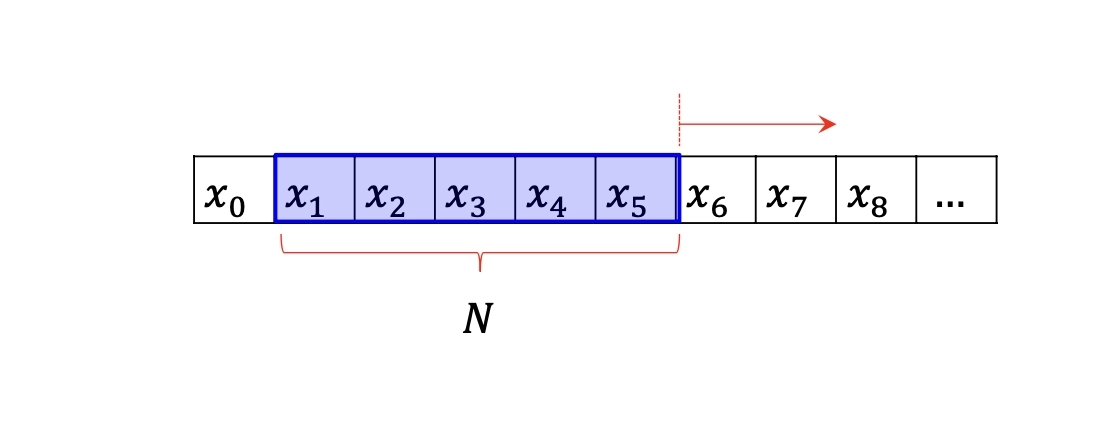  
  

- 일정 개수의 연속된 관측값을 평균 내고, 구간을 한 칸씩 이동하며 평균을 계산
- **이동평균 구간 크기**는 한 번에 평균을 계산할 데이터의 개수를 의미
- 구간이 작으면 최근 변화에 빠르게 반응하지만 노이즈가 많이 남음
- 구간이 크면 추세가 매끄럽게 나타나지만 급격한 변화에 늦게 반응
- 추세 파악, 계절성 완화, 결측치·이상치 대치 등에 활용

### 이동평균의 종류

**1. 단순 이동평균**

- 구간 안의 모든 관측값에 동일한 가중치를 부여
- 계산이 간단하지만 최근 변화를 빠르게 반영하기 어려움

**2. 가중 이동평균**

- 최근 관측값일수록 더 큰 가중치를 부여
- 단순 이동평균보다 최근 변화에 빠르게 반응하지만 가중치를 직접 정해야 함

**3. 지수 이동평균**

- 최근 값에 큰 가중치를 주고 과거로 갈수록 가중치가 지수적으로 감소
- 현재 관측값과 직전 지수 이동평균을 결합해 계산
- 가중치 계수가 클수록 최근 값을 더 중요하게 반영
- 과거 정보를 활용하면서 계산이 효율적이지만 계수 설정이 필요

## 2-3. 요소분해

> 여러 변동 요인이 섞인 시계열을 **추세, 계절, 잔차** 등의 구성 요소로 분리하는 과정

- 순환 요인은 구분이 어려워 추세에 포함하는 경우가 많음
- 각 변동의 원인을 이해하고 계절 조정이나 잔차 기반 이상치 탐지에 활용

### 분해 모형

**1. 가법 모형**

- **시계열 = 추세 + 계절 + 잔차**
- 각 요인의 영향이 더해지는 구조
- 추세 수준이 달라져도 계절 변동의 크기가 일정할 때 적합

**2. 승법 모형**

- **시계열 = 추세 × 계절 × 잔차**
- 데이터의 크기가 커질수록 계절 변동 폭도 비례해 커지는 구조
- 로그 변환으로 곱셈 구조를 덧셈 구조처럼 다룰 수 있음

### 요소분해 방법

**1. 이동평균 기반 분해**

1. 이동평균으로 추세 추출
2. 원본 데이터에서 추세 제거
3. 같은 계절에 해당하는 값들을 평균 내 계절 요인 추정
4. 추세와 계절을 제거하고 남은 값을 잔차로 계산

- 구조가 단순하지만 시간에 따라 변하는 계절 패턴을 유연하게 반영하기 어려움

**2. STL 분해**

- 주변 데이터에 가중치를 부여한 국소 회귀를 이용해 추세와 계절 요인 추정
- 내부 반복으로 추세와 계절을 번갈아 계산해 점차 보정
- 외부 반복으로 잔차가 큰 관측값의 가중치를 줄여 이상치 영향을 완화
- 변화하는 패턴을 유연하게 반영하고 이상치에 비교적 강건

# 3. 정상성 판단

## 3-1. 정상성이란?

> **정상성**: 시계열의 평균, 분산, 자기상관 구조 등 통계적 특성이 시간에 따라 변하지 않는 성질

- 일정한 평균을 중심으로 비슷한 폭으로 변동하는 시계열이 정상 시계열
- 추세가 있거나 계절성이 반복되고 변동 폭이 달라지면 비정상 시계열일 수 있음
- 과거 패턴을 미래 예측에 활용하기 위해 정상성 판단이 중요
- 비정상 시계열은 차분이나 변환을 통해 정상성을 확보한 뒤 모델링

## 3-2. 강한 정상성과 약한 정상성

### 1. 강한 정상성

- 시계열의 **확률분포 전체**가 시간에 따라 변하지 않는 상태
- 평균, 분산뿐 아니라 분포의 모든 특성이 동일해야 함
- 현실 데이터에서는 만족하기 어려운 엄격한 조건

### 2. 약한 정상성

- 분포 전체가 아니라 **평균, 분산, 자기공분산**에 관한 조건을 만족하는 상태
- 평균이 시간에 따라 일정
- 분산이 시간에 따라 일정하고 유한
- 자기공분산은 실제 시점이 아니라 두 시점 사이의 **시차**에만 의존

→ 실제 시계열 분석에서는 주로 약한 정상성을 기준으로 판단

## 3-3. 정상성 판단 방법

### 1. 시각적 판단

- 정상 시계열은 일정한 평균 주위에서 비슷한 폭으로 변동
- 비정상 시계열은 지속적인 추세, 반복적인 계절성 또는 분산 변화가 나타남
- 자기상관 그래프가 빠르게 0에 가까워지면 정상성의 신호로 볼 수 있음
- 자기상관이 오랫동안 천천히 감소하면 비정상 가능성을 고려

### 2. 단위근 검정

> **단위근**: 과거 충격의 영향이 사라지지 않고 계속 누적되는 성질과 관련된 개념

- 단위근이 존재하면 평균으로 돌아오지 않고 분산이 커지는 비정상 시계열이 될 수 있음
- 시각적 판단을 보완하기 위해 통계적 검정 사용

**ADF 검정**

- 귀무가설: 단위근이 존재하는 **비정상 시계열**
- 대립가설: 단위근이 없는 **정상 시계열**
- 유의확률이 0.05 미만이면 귀무가설을 기각하고 정상으로 판단

**KPSS 검정**

- 귀무가설: **정상 시계열**
- 대립가설: **비정상 시계열**
- 유의확률이 0.05 미만이면 귀무가설을 기각하고 비정상으로 판단

**검정 결과 해석**

- 두 검정 모두 정상 → 모델링 진행
- 두 검정 모두 비정상 → 차분 등 정상성 확보 후 재검정
- ADF는 비정상, KPSS는 정상 → 추세 정상 가능성을 고려해 추세 제거 후 재검정
- ADF는 정상, KPSS는 비정상 → 차분 필요성을 검토하고 재검정

→ 두 검정은 귀무가설이 반대이므로 함께 사용해 판단을 보완

## 3-4. 정상성 확보 방법

### 1. 추세 제거

**차분**

> 현재 값에서 이전 시점의 값을 빼고, 값 자체가 아닌 변화량을 분석하는 방법

- 1차 차분: 현재 값 − 직전 시점 값
- 2차 차분: 1차 차분 결과를 한 번 더 차분
- 추세와 누적된 충격을 완화해 평균이 일정한 시계열로 변환
- 차분을 지나치게 반복하면 불필요한 변동이 발생할 수 있어 최소 횟수만 적용
- 차분한 값으로 예측한 뒤에는 **역차분**으로 원래 단위의 예측값 복원

### 2. 계절성 제거

**계절 차분**

- 현재 값에서 한 계절 주기 전의 값을 빼는 방법
- 월별 자료라면 올해 8월과 작년 8월처럼 같은 계절 위치의 값을 비교
- 반복적인 계절 효과를 제거해 변화량을 분석

### 3. 분산 안정화

**로그 변환**

- 큰 값은 많이, 작은 값은 상대적으로 적게 축소해 변동 폭을 안정화
- 데이터 크기에 비례해 변동 폭이 커지는 경우 유용
- 곱셈 형태의 승법 모형을 덧셈 형태로 바꾸는 효과
- 0이나 음수에는 바로 적용할 수 없고 모든 분산 변화를 해결하는 것은 아님

→ 추세, 계절성, 분산 변화 중 어떤 원인으로 정상성이 깨졌는지에 따라 적절한 방법 선택

# 4. 단변량 시계열 분석

> 하나의 변수에 대해 자기 자신의 과거 기록으로 현재와 미래의 값을 설명하고 예측하는 방법

## 4-1. 안정적 시계열 분석

- 일정한 평균으로 돌아가는 **정상 시계열**에 적용
- **관측값**은 실제 기록된 결과이고, **충격**은 해당 시점에 새로 발생한 예측하기 어려운 변동

### 1. 자기회귀 모형 AR

> 현재 값을 **자기 자신의 과거 값**으로 설명하는 모형

- 시계열의 자기상관성을 이용
- 차수 p는 현재 값을 설명하는 데 사용하는 과거 시점의 개수
- AR 1은 바로 직전 시점의 값과 현재 충격을 이용
- 과거 값에 충격의 영향이 포함되어 있어 충격 효과가 시간이 지나며 서서히 감소

### 2. 이동평균 모형 MA

> 현재 값을 **현재와 과거의 충격**으로 설명하는 모형

- 차수 q는 현재 값에 반영하는 과거 충격의 개수
- MA 1은 현재 충격과 직전 시점의 충격을 활용
- 과거 충격의 영향이 정해진 시차까지만 이어진 뒤 사라짐
- 전처리에서 사용하는 이동평균과 달리 **과거 관측값의 평균이 아니라 과거 충격**을 활용

**AR과 MA의 차이**

- AR: 과거 관측값의 영향이 누적되어 점차 약해지는 방식
- MA: 과거 충격 자체의 영향이 일정 기간만 지속되는 방식

### 모형의 전제 조건

**1. 정상성**

- 충격을 받아도 시간이 지나면 평균 수준으로 돌아오는 성질
- AR 1은 계수의 절댓값이 1보다 작아야 정상성을 만족
- 일반적인 MA 모형은 유한한 충격의 영향만 반영하므로 정상성 만족

**2. 가역성**

- 실제 관측값을 이용해 과거 충격을 안정적으로 추정할 수 있는 성질
- AR 모형은 충격을 관측값으로 표현할 수 있어 가역성 만족
- MA 1은 계수의 절댓값이 1보다 작아야 가역성 만족
- 데이터의 정상성은 단위근 검정, 추정된 모형의 정상성과 가역성은 계수 조건으로 확인

### 3. 자기회귀 이동평균 모형 ARMA

> 현재 값을 **과거 관측값과 과거 충격**을 함께 이용해 설명하는 모형

- AR과 MA를 결합한 구조
- 차수 p는 과거 값의 개수, q는 과거 충격의 개수
- 두 패턴을 동시에 반영해 더 적은 계수로 설명할 수 있음
- 정상성과 가역성 조건을 함께 확인해야 함

### 차수 결정 방법

**자기상관함수 ACF**

- 현재 값과 시차별 과거 값 사이의 상관관계를 나타냄
- 중간 시점을 거쳐 전달된 영향까지 포함
- 주로 MA 모형의 차수 q를 판단하는 데 활용

**부분자기상관함수 PACF**

- 중간 시점의 영향을 제거한 뒤 현재와 과거 값 사이의 직접적인 상관관계를 나타냄
- 주로 AR 모형의 차수 p를 판단하는 데 활용

**그래프 해석**

- ACF가 서서히 감소하고 PACF가 특정 시차 이후 급격히 작아짐 → AR 모형 고려
- ACF가 특정 시차 이후 급격히 작아지고 PACF가 서서히 감소 → MA 모형 고려
- 두 함수의 패턴을 함께 살펴 ARMA 차수 선택

## 4-2. 불안정 시계열 분석

- 추세나 계절성이 있어 **정상성을 만족하지 않는 시계열**에 적용
- 차분 또는 계절 차분으로 정상성을 확보한 뒤 과거 값과 충격을 모델링

### 1. 자기회귀 누적 이동평균 모형 ARIMA

> ARMA 모형에 **차분 과정**을 추가해 비정상 시계열을 분석하는 모형

- p: 자기회귀 차수
- d: 차분 횟수
- q: 이동평균 차수

**모형의 흐름**

1. 원래 시계열을 차분해 변화량 생성
2. 변화량을 ARMA로 분석하고 예측
3. 예측한 변화량을 역차분해 원래 단위의 미래 값 계산

**특수한 경우**

- **랜덤워크**: 현재 값 = 직전 값 + 현재 충격
  - 충격의 기대값을 0으로 보면 다음 값의 예측은 현재 값
- **표류를 포함하는 랜덤워크**: 직전 값에 충격과 일정한 증가·감소량이 더해지는 모형
  - 시간에 따라 한 방향으로 이동하는 흐름을 반영

### 2. 계절 자기회귀 누적 이동평균 모형 SARIMA

> ARIMA에 **계절 차분, 계절 자기회귀, 계절 이동평균**을 추가한 모형

- 일반 차분으로 추세를 제거하고 계절 차분으로 반복적인 계절 효과 제거
- 비계절 요소와 계절 요소를 함께 활용해 미래 값 예측

**하이퍼파라미터**

- p: 비계절 자기회귀 차수
- d: 비계절 차분 횟수
- q: 비계절 이동평균 차수
- P: 계절 자기회귀 차수
- D: 계절 차분 횟수
- Q: 계절 이동평균 차수
- m: 계절 주기 → 월별 연간 계절성은 12, 분기별은 4

**모형의 흐름**

1. 추세와 계절성을 제거하도록 필요한 차분 수행
2. 직전 시점과 과거 같은 계절의 값 및 충격을 활용해 변화량 예측
3. 역차분해 실제 미래 값으로 복원

### 모형의 차수 결정

- ADF, KPSS 등으로 정상성 확인 후 차분 횟수 d와 D 결정
- ACF와 PACF 그래프로 자기회귀와 이동평균 차수 후보 탐색
- **AIC, BIC**처럼 복잡도와 적합도를 고려한 정보 기준을 이용해 후보 모형 비교
- 정보 기준은 낮을수록 적절한 모형을 선택하는 데 유리
- 차수 후보를 바꿔가며 비교하는 탐색으로 최종 모형 선정

# 5. 다변량 시계열 분석

> 여러 변수의 현재 값을 **자기 자신의 과거와 다른 변수의 과거**를 함께 이용해 예측하는 방법

## 5-1. 벡터 자기회귀 모형 VAR

- 자기회귀 모형을 여러 변수로 확장한 형태
- 변수마다 예측식이 존재하고 각 예측식에 여러 변수의 과거 값이 포함됨
- 예: 오늘 판매량을 어제 판매량과 어제 광고비로 예측하고, 오늘 광고비도 두 변수의 과거 값으로 예측
- 변수들이 서로 영향을 주고받는 관계를 분석하는 데 유용

**적합한 경우**

- 변수 사이에 양방향 영향이 존재
- 변수들이 정상성을 만족하거나 차분으로 정상성을 확보할 수 있음
- 변수 수가 적고 충분한 관측 데이터가 있음

**한계**

- 변수 수가 증가할수록 추정할 계수가 빠르게 늘어나 데이터와 계산량 필요
- 한 방향의 영향만 존재하는 경우에는 다른 모형이 더 적합할 수 있음
- 복잡한 비선형 관계를 표현하는 데 한계

### 그레인저 인과관계 검정

> 한 변수의 과거 정보가 **다른 변수의 미래 값을 예측하는 데 도움이 되는지** 확인하는 검정

1. 예측 대상 변수 자신의 과거 값만 사용한 모형 구성
2. 다른 변수의 과거 값까지 추가한 모형과 비교
3. 추가한 변수가 예측에 유의미한 도움을 주는지 판단

- 귀무가설: 다른 변수의 과거 값이 예측에 도움을 주지 않음
- 유의확률이 0.05 미만이면 귀무가설을 기각하고 예측에 도움이 된다고 판단
- **예측에 도움이 된다는 의미이지 실제 인과관계를 증명하는 것은 아님**

### VAR 분석 방법

**1. 충격 반응 함수**

- 하나의 변수에 충격이 발생했을 때 다른 변수가 시간에 따라 어떻게 반응하는지 분석
- 영향의 크기, 방향, 지속 기간을 확인
- 예: 광고비 증가가 이후 며칠 동안 판매량에 미치는 변화

**2. 예측오차 분산 분해**

- 미래 예측 오차가 각 변수의 충격에 의해 얼마나 설명되는지 비율로 분석
- 예측 기간이 길어지면서 다른 변수의 충격이 차지하는 비중을 확인

→ 충격 반응 함수는 **어떻게 반응하는지**, 예측오차 분산 분해는 **각 충격의 영향이 얼마나 큰지**를 보여 줌

# 6. 딥러닝을 활용한 시계열 분석

- 전통적인 통계 모델은 긴 데이터 처리와 복잡한 비선형 패턴 학습에 한계
- 딥러닝은 시계열의 순차적 관계와 복잡한 패턴을 학습해 미래 값을 예측

## 6-1. 순환 신경망 계열

### 1. RNN

- 이전 시점의 정보를 현재로 전달하는 순환 구조의 신경망
- 짧은 시계열의 순차적 패턴을 학습하는 데 활용
- 긴 시계열에서는 오래된 정보의 영향을 학습하기 어려움

### 2. LSTM

- 기억을 제어하는 구조를 사용해 **장기 의존성**을 학습
- 오래전 정보가 현재 예측에 중요한 데이터에 활용
- 구조가 복잡하고 학습 비용이 큰 편

### 3. GRU

- LSTM의 구조를 단순화한 모형
- 비교적 빠르게 학습하면서 시계열의 중요한 정보 유지
- 긴 의존성 학습에서는 LSTM보다 약할 수 있음

→ 순환 신경망은 순차적 데이터에 적합하지만 매우 긴 시계열에서 학습이 어렵고 병렬 처리 효율이 낮음

## 6-2. 트랜스포머 계열

### 1. Informer

- 불필요한 연산을 줄여 계산 복잡도를 낮춘 구조
- **매우 긴 시계열**의 장기 예측에 적합
- 예: 장기간 전력 수요 예측

### 2. Autoformer

- **추세와 계절성 요소분해**를 신경망 구조에 결합
- 계절성과 주기적 패턴이 뚜렷한 데이터 예측에 유리
- 예: 월별 판매량 예측

### 3. TFT

- 과거 시계열과 날씨, 휴일 등 다양한 외부 변수를 함께 활용
- 어떤 변수가 예측에 중요했는지 해석할 수 있는 구조
- 설명이 중요한 유통·수요 예측에 유용하지만 학습 시간이 오래 걸릴 수 있음

## 6-3. 파운데이션 모델

> 대규모 데이터로 미리 학습해 다양한 시계열 예측 문제에 활용할 수 있는 범용 모델

- 특정 문제 하나에만 맞춘 모델이 아니라 여러 종류의 데이터와 과제에 적용
- 필요에 따라 추가 학습으로 개별 예측 문제에 맞게 조정

**주요 유형**

- **대규모 언어 모델 활용**: 시계열 정보를 지시문이나 텍스트 형태로 제공해 분석 및 예측에 활용
- **시계열 전용 범용 모델**: 시계열 데이터로 사전 학습한 모델
  - 예: TimeGPT, TimesFM, Moirai, Chronos

**언어 모델 활용 방식**

- 기존 모델을 별도 학습 없이 지시문을 통해 활용
- 시계열 데이터로 언어 모델을 추가 학습
- 숫자 형태의 시계열을 증가 추세나 주기성 등 텍스트로 변환해 활용

## 6-4. 모델 선택 기준

- **데이터가 적고 구조가 단순한 경우**: ARIMA 등 통계 모델이나 간단한 순환 신경망 고려
- **중간 길이의 시계열**: LSTM, GRU 등으로 과거 정보 학습
- **매우 긴 시계열**: Informer 등 장기 시계열 모델 고려
- **계절성이 뚜렷한 데이터**: Autoformer 활용
- **외부 변수가 많고 해석이 중요한 경우**: TFT 활용
- **다양한 데이터에 범용적으로 적용하는 경우**: 사전 학습된 파운데이션 모델 활용

→ 모델이 복잡하다고 항상 성능이 좋은 것은 아니므로 데이터 크기, 예측 기간, 계절성, 변수 수, 계산 비용과 해석 가능성을 함께 고려해야 함
